IQAE tutorial:
- IQAE u vary the epsilon (error) and the alpha (confidence level)
- qubit count is only relevant in state preperation

In [1]:
"""
Definition of the Bernoulli A and Q operators as quantum circuits.
"""

import numpy as np
from qiskit.circuit import QuantumCircuit


class BernoulliA(QuantumCircuit):
    """A circuit representing the Bernoulli A operator."""

    def __init__(self, probability):
        super().__init__(1)  # circuit on 1 qubit

        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)


class BernoulliQ(QuantumCircuit):
    """A circuit representing the Bernoulli Q operator."""

    def __init__(self, probability):
        super().__init__(1)  # circuit on 1 qubit

        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        # implement the efficient power of Q
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k
    

In [12]:
from qiskit_algorithms import EstimationProblem

p = 0.13
A = BernoulliA(p)
Q = BernoulliQ(p)

problem = EstimationProblem(
    state_preparation=A,  # A operator
    grover_operator=Q,  # Q operator
    objective_qubits=[0],  # the "good" state Psi1 is identified as measuring |1> in qubit 0
)

In [13]:
from qiskit_algorithms import EstimationProblem

problem = EstimationProblem(
    state_preparation=A,  # A operator
    grover_operator=Q,  # Q operator
    objective_qubits=[0],  # the "good" state Psi1 is identified as measuring |1> in qubit 0
)

In [14]:
from qiskit.primitives import Sampler

sampler = Sampler()

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_7576\2087805081.py:3: DeprecationWarning: The class ``qiskit.primitives.sampler.Sampler`` is deprecated as of qiskit 1.2. It will be removed no earlier than 3 months after the release date. All implementations of the `BaseSamplerV1` interface have been deprecated in favor of their V2 counterparts. The V2 alternative for the `Sampler` class is `StatevectorSampler`.
  sampler = Sampler()


In [15]:
from qiskit_algorithms import IterativeAmplitudeEstimation

iae = IterativeAmplitudeEstimation(
    epsilon_target=0.01,   # target precision
    alpha=0.05,            # 95% confidence interval
    sampler=sampler,
)

result = iae.estimate(problem)   # run ONCE, reuse result everywhere

print("Epsilon target:        ", result.epsilon_target)
print("Epsilon achieved:      ", result.epsilon_estimated)
print("Estimate:              ", result.estimation)
print("Confidence interval:   ", result.confidence_interval)
print("Total oracle queries:  ", result.num_oracle_queries)
print("Num iterations:        ", len(result.powers))
print("Shots per iteration:   ", result.shots)
print("Powers (k per round):  ", result.powers)
print("Estimate intervals:    ", result.estimate_intervals)
print("Theta intervals:       ", result.theta_intervals)        # Grover iterations per round

Epsilon target:         None
Epsilon achieved:       0.0
Estimate:               0.13
Confidence interval:    [np.float64(0.13), np.float64(0.13)]
Total oracle queries:   0
Num iterations:         2
Shots per iteration:    None
Powers (k per round):   [0, 0]
Estimate intervals:     [[0.0, 1.0], [np.float64(0.13), np.float64(0.13)]]
Theta intervals:        [[0, 0.25], [np.float64(0.11741273452659019), np.float64(0.11741273452659019)]]



🚀 IQAE Sweep | Metric: num_oracle_queries | Total runs: 3125
   α values : [0.001, 0.005, 0.01, 0.05, 0.1]
   p range  : [0.010 → 0.500] (25 pts)
   ε range  : [0.0010 → 0.1000] (25 pts)


  α sweep 1/5  |  α = 0.001  |  Grid: 25p × 25ε = 625 combos
  [░░░░░░░░░░░░░░░░░░░░]   0.8% | Run   25/3125 | α=0.00  p=0.010 (1/25)  ε=0.1000 (25/25) | Elapsed 5s  ETA 10.2min
  ✅ p=0.010 done | num_oracle_queries: mean=5611.5200  min=0.0000  max=55296.0000
  [░░░░░░░░░░░░░░░░░░░░]   1.6% | Run   50/3125 | α=0.00  p=0.030 (2/25)  ε=0.1000 (25/25) | Elapsed 10s  ETA 10.0min
  ✅ p=0.030 done | num_oracle_queries: mean=16424.9600  min=0.0000  max=321536.0000
  [░░░░░░░░░░░░░░░░░░░░]   2.4% | Run   75/3125 | α=0.00  p=0.051 (3/25)  ε=0.1000 (25/25) | Elapsed 14s  ETA 9.8minn
  ✅ p=0.051 done | num_oracle_queries: mean=6840.3200  min=0.0000  max=69632.0000
  [░░░░░░░░░░░░░░░░░░░░]   3.2% | Run  100/3125 | α=0.00  p=0.071 (4/25)  ε=0.1000 (25/25) | Elapsed 19s  ETA 9.6minn
  ✅ p=0.071 done | num_oracle_

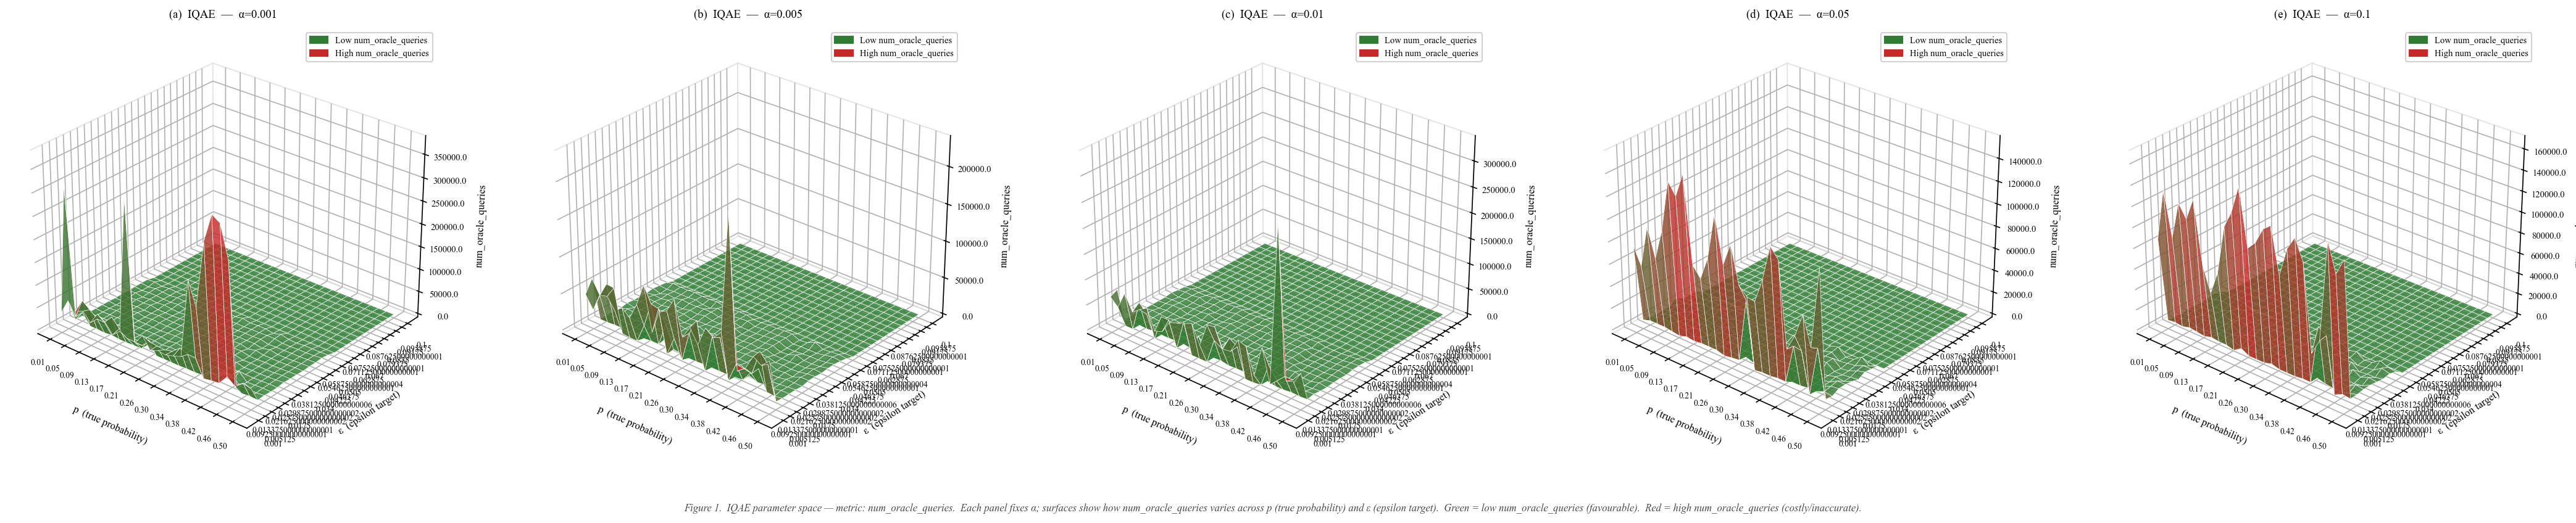

saved → iqae_sweep_num_oracle_queries.pdf


In [31]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import rcParams
import matplotlib.ticker as ticker
import time
import sys

# ── Publication style ─────────────────────────────────────────────────────────
rcParams.update({
    'font.family':     'serif',
    'font.serif':      ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'font.size':       10,
    'axes.titlesize':  10,
    'axes.labelsize':  9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'figure.dpi':      150,
})

# ── Parameter grids ───────────────────────────────────────────────────────────
p_values       = np.linspace(0.01, 0.50, 25)
epsilon_values = np.linspace(0.001, 0.1, 25)
alpha_values   = [0.001, 0.005, 0.01,0.05, 0.1]
METRIC         = "num_oracle_queries"   # swap to any supported metric

# ── Axis meshgrid ─────────────────────────────────────────────────────────────
P, E           = np.meshgrid(p_values, epsilon_values, indexing="ij")

# ── Tick formatting for epsilon axis (log-like labels) ───────────────────────
etick_pos    = epsilon_values
etick_labels = [str(e) for e in epsilon_values]

# ── Progress helpers ──────────────────────────────────────────────────────────
total_runs  = len(alpha_values) * len(p_values) * len(epsilon_values)
run_counter = 0
start_time  = time.time()

def format_eta(seconds):
    if seconds < 60:
        return f"{seconds:.0f}s"
    elif seconds < 3600:
        return f"{seconds/60:.1f}min"
    else:
        return f"{seconds/3600:.1f}hr"

def print_progress(run_counter, total_runs, alpha, p, i, eps, j, start_time):
    elapsed     = time.time() - start_time
    avg_per_run = elapsed / run_counter if run_counter > 1 else 0
    remaining   = avg_per_run * (total_runs - run_counter)
    pct         = 100 * run_counter / total_runs
    bar_len     = 20
    filled      = int(bar_len * run_counter / total_runs)
    bar         = "█" * filled + "░" * (bar_len - filled)
    line = (
        f"\r  [{bar}] {pct:5.1f}% | "
        f"Run {run_counter:>4}/{total_runs} | "
        f"α={alpha:.2f}  "
        f"p={p:.3f} ({i+1}/{len(p_values)})  "
        f"ε={eps:.4f} ({j+1}/{len(epsilon_values)}) | "
        f"Elapsed {format_eta(elapsed)}  ETA {format_eta(remaining)}"
    )
    sys.stdout.write(line)
    sys.stdout.flush()

# ── Sweep function ────────────────────────────────────────────────────────────
def run_sweep_verbose(alpha, alpha_idx):
    global run_counter

    Z = np.zeros((len(p_values), len(epsilon_values)))

    print(f"\n{'='*70}")
    print(f"  α sweep {alpha_idx+1}/{len(alpha_values)}  |  "
          f"α = {alpha}  |  "
          f"Grid: {len(p_values)}p × {len(epsilon_values)}ε "
          f"= {len(p_values)*len(epsilon_values)} combos")
    print(f"{'='*70}")

    for i, p in enumerate(p_values):
        for j, eps in enumerate(epsilon_values):
            run_counter += 1

            try:
                A       = BernoulliA(p)
                Q       = BernoulliQ(p)
                problem = EstimationProblem(
                    state_preparation=A,
                    grover_operator=Q,
                    objective_qubits=[0],
                )
                iae = IterativeAmplitudeEstimation(
                    epsilon_target=eps,
                    alpha=alpha,
                    sampler=sampler,
                )
                result = iae.estimate(problem)

                if METRIC == "epsilon_achieved":
                    Z[i, j] = result.epsilon_estimated
                elif METRIC == "num_oracle_queries":
                    Z[i, j] = result.num_oracle_queries
                elif METRIC == "abs_error":
                    Z[i, j] = abs(result.estimation - p)
                elif METRIC == "num_iterations":
                    Z[i, j] = len(result.powers)

            except Exception as ex:
                sys.stdout.write(
                    f"\n  ⚠️  FAILED | α={alpha} p={p:.3f} ε={eps:.4f} → {ex}\n"
                )
                Z[i, j] = np.nan

            print_progress(run_counter, total_runs, alpha, p, i, eps, j, start_time)

        # ── per-p row summary ─────────────────────────────────────────────
        sys.stdout.write(
            f"\n  ✅ p={p:.3f} done | "
            f"{METRIC}: mean={np.nanmean(Z[i,:]):.4f}  "
            f"min={np.nanmin(Z[i,:]):.4f}  "
            f"max={np.nanmax(Z[i,:]):.4f}\n"
        )
        sys.stdout.flush()

    # ── per-alpha summary ─────────────────────────────────────────────────
    print(f"\n{'─'*70}")
    print(f"  α={alpha} complete | "
          f"{METRIC}: mean={np.nanmean(Z):.4f}  "
          f"min={np.nanmin(Z):.4f}  "
          f"max={np.nanmax(Z):.4f}")
    print(f"{'─'*70}\n")

    return Z

# ── Face colour helper (high = red, low = green) ──────────────────────────────
def build_facecolors_metric(Z):
    """
    Green  → low metric value  (good: low error / low oracle cost)
    Red    → high metric value (bad:  high error / high oracle cost)
    """
    Z_min = np.nanmin(Z)
    Z_max = np.nanmax(Z)
    rows, cols = Z.shape
    fc = np.empty((rows - 1, cols - 1, 4))
    for i in range(rows - 1):
        for j in range(cols - 1):
            val  = Z[i, j]
            norm = (val - Z_min) / (Z_max - Z_min + 1e-12)   # 0=best, 1=worst
            # lerp green → red
            r = 0.18 + norm * (0.78 - 0.18)
            g = 0.49 + norm * (0.16 - 0.49)
            b = 0.20 + norm * (0.16 - 0.20)
            fc[i, j] = (r, g, b, 0.82)
    return fc

# ── Axis styler ───────────────────────────────────────────────────────────────
def style_ax(ax, title):
    ax.set_xlabel('p  (true probability)', labelpad=6, fontsize=8)
    ax.set_ylabel('ε  (epsilon target)',   labelpad=6, fontsize=8)
    ax.set_zlabel(METRIC,                  labelpad=6, fontsize=8)
    ax.set_title(title, pad=8, fontweight='normal', fontsize=9)
    ax.set_xticks(p_values[::2])
    ax.set_xticklabels([f"{p:.2f}" for p in p_values[::2]], fontsize=6.5)
    ax.set_yticks(etick_pos)
    ax.set_yticklabels(etick_labels, fontsize=6.5)
    ax.zaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('#cccccc')
    ax.yaxis.pane.set_edgecolor('#cccccc')
    ax.zaxis.pane.set_edgecolor('#cccccc')
    ax.grid(True, linestyle='--', linewidth=0.35, alpha=0.5)
    ax.view_init(elev=28, azim=-50)

# ── Legend handles ────────────────────────────────────────────────────────────
h_low  = mpatches.Patch(color=(0.18, 0.49, 0.20), label=f'Low {METRIC}')
h_high = mpatches.Patch(color=(0.78, 0.16, 0.16), label=f'High {METRIC}')

# ── Main sweep + plot ─────────────────────────────────────────────────────────
print(f"\n🚀 IQAE Sweep | Metric: {METRIC} | Total runs: {total_runs}")
print(f"   α values : {alpha_values}")
print(f"   p range  : [{p_values[0]:.3f} → {p_values[-1]:.3f}] ({len(p_values)} pts)")
print(f"   ε range  : [{epsilon_values[0]:.4f} → {epsilon_values[-1]:.4f}] ({len(epsilon_values)} pts)\n")

# one column per alpha
fig = plt.figure(figsize=(6 * len(alpha_values), 6))
fig.patch.set_facecolor('white')

panel_labels = "abcdefghij"

for idx, alpha in enumerate(alpha_values):
    Z  = run_sweep_verbose(alpha, idx)
    fc = np.pad(
        build_facecolors_metric(Z),
        ((0, 1), (0, 1), (0, 0)),
        mode='edge'
    )

    ax = fig.add_subplot(1, len(alpha_values), idx + 1, projection='3d')
    ax.plot_surface(
        P, E, Z,
        facecolors=fc,
        edgecolor='white',
        linewidth=0.3,
        shade=False
    )
    style_ax(
        ax,
        f'({panel_labels[idx]})  IQAE  —  α={alpha}'
    )
    ax.legend(
        handles=[h_low, h_high],
        loc='upper right',
        fontsize=7,
        framealpha=0.9,
        edgecolor='#cccccc'
    )

# ── Figure caption ────────────────────────────────────────────────────────────
fig.text(
    0.5, 0.005,
    f'Figure 1.  IQAE parameter space — metric: {METRIC}.  '
    f'Each panel fixes α; surfaces show how {METRIC} varies '
    f'across p (true probability) and ε (epsilon target).  '
    f'Green = low {METRIC} (favourable).  Red = high {METRIC} (costly/inaccurate).',
    ha='center', va='bottom', fontsize=8, style='italic', color='#444444'
)

# ── Final summary + save ──────────────────────────────────────────────────────
total_time = time.time() - start_time
print(f"\n{'='*70}")
print(f"  ✅ All sweeps done | Total time: {format_eta(total_time)}")
print(f"  📊 Saving → iqae_sweep_{METRIC}.pdf")
print(f"{'='*70}\n")

plt.subplots_adjust(left=0.04, right=0.96, hspace=0.35, wspace=0.15)
plt.savefig(f'iqae_sweep_{METRIC}.pdf', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()
print(f"saved → iqae_sweep_{METRIC}.pdf")